<a href="https://colab.research.google.com/github/fadzankerim/Network-Intrusion-Detection-System/blob/cleaning-transformation/Cleaning_Transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import os
import sys
import json
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(' Biblioteke učitane!')

 Biblioteke učitane!


In [23]:
# ID podijeljenog foldera na Google Drive-u
GDRIVE_FOLDER_ID = '1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm'
GDRIVE_FOLDER_URL = f'https://drive.google.com/drive/folders/{GDRIVE_FOLDER_ID}'

# Pokušaj montiranja Google Drive-a
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception as e:
    print(f'ℹ️ Google Drive mount preskočen ili nije na Colab-u: {e}')

def resolve_dataset_directory(folder_id=GDRIVE_FOLDER_ID):
    candidate_paths = [
        Path('/content/Dataset'),
        Path('/content/drive/MyDrive/MPVI/Dataset'),
        Path('/content/drive/MyDrive/Dataset'),
        Path('./Dataset'),
        Path('../Dataset')
    ]
    for p in candidate_paths:
        if p.exists() and len(list(p.glob('**/UNSW_NB15_training-set.csv'))) > 0:
            found_file = list(p.glob('**/UNSW_NB15_training-set.csv'))[0]
            ds_root = found_file.parent.parent if found_file.parent.name == 'Training and Testing Sets' else found_file.parent
            print(f'✅ Dataset pronađen na: {ds_root}')
            return str(ds_root)

    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        found = list(drive_root.glob('**/UNSW_NB15_training-set.csv'))
        if found:
            ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
            print(f'✅ Dataset pronađen na Drive-u: {ds_root}')
            return str(ds_root)

    print(' Preuzimam dataset sa Google Drive linka...')
    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
        import gdown
    download_dir = Path('/content/Dataset')
    download_dir.mkdir(parents=True, exist_ok=True)
    try:
        gdown.download_folder(id=folder_id, output=str(download_dir), quiet=False, use_cookies=False)
    except Exception:
        gdown.download_folder(url=GDRIVE_FOLDER_URL, output=str(download_dir), quiet=False)
    found = list(download_dir.glob('**/UNSW_NB15_training-set.csv'))
    if found:
        ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
        return str(ds_root)
    return str(download_dir)

DATASET_PATH = resolve_dataset_directory()
if not DATASET_PATH.endswith('/'):
    DATASET_PATH += '/'

train_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_training-set.csv'))
test_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_testing-set.csv'))
TRAIN_PATH = str(train_matches[0]) if train_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH = str(test_matches[0]) if test_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'

print(f'\n📂 DATASET_PATH: {DATASET_PATH}')
print(f'📄 TRAIN_PATH:   {TRAIN_PATH}')
print(f'📄 TEST_PATH:    {TEST_PATH}')

✅ Dataset pronađen na: /content/drive/MyDrive/MPVI/Dataset

📂 DATASET_PATH: /content/drive/MyDrive/MPVI/Dataset/
📄 TRAIN_PATH:   /content/drive/MyDrive/MPVI/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv
📄 TEST_PATH:    /content/drive/MyDrive/MPVI/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv


In [24]:
# Učitavanje training i testing seta
df_train_raw = pd.read_csv(TRAIN_PATH)
df_test_raw  = pd.read_csv(TEST_PATH)

df_train = df_train_raw.copy()
df_test  = df_test_raw.copy()

# Označavanje izvora
df_train['source'] = 'train'
df_test['source']  = 'test'

print(f'Training: {df_train.shape[0]:,} zapisa, {df_train.shape[1]} kolona')
print(f'Testing:  {df_test.shape[0]:,} zapisa, {df_test.shape[1]} kolona')
print(f'Ukupno:   {df_train.shape[0] + df_test.shape[0]:,} zapisa')
display(df_train.head())

Training: 175,341 zapisa, 46 kolona
Testing:  82,332 zapisa, 46 kolona
Ukupno:   257,673 zapisa


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,train
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,train
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,train
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0,train
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,train


In [25]:
# Sačuvaj originalne oblike za poređenje u rezimeu
original_train_shape = df_train.shape
original_test_shape  = df_test.shape

TARGET = 'label'
TARGET_MULTI = 'attack_cat'
CAT_FEATURES = ['proto', 'service', 'state']
BINARY_FEATURES = ['is_ftp_login', 'is_sm_ips_ports']

print(f'Originalni train oblik: {original_train_shape}')
print(f'Originalni test oblik:  {original_test_shape}')

Originalni train oblik: (175341, 46)
Originalni test oblik:  (82332, 46)


In [26]:
# 'id' je samo redni broj zapisa i ne nosi informaciju o saobraćaju
DROP_COLUMNS = ['id']

df_train = df_train.drop(columns=DROP_COLUMNS, errors='ignore')
df_test  = df_test.drop(columns=DROP_COLUMNS, errors='ignore')

print(f'✅ Uklonjene kolone: {DROP_COLUMNS}')
print(f'Train: {df_train.shape} | Test: {df_test.shape}')

✅ Uklonjene kolone: ['id']
Train: (175341, 45) | Test: (82332, 45)


In [27]:
def report_missing(df, name):
    num = df.select_dtypes(include=[np.number])
    n_nan = df.isnull().sum().sum()
    n_inf = np.isinf(num).sum().sum()
    neg_cols = [c for c in num.columns if (num[c] < 0).any()]
    print(f'{name}: NaN = {n_nan}, inf = {n_inf}, kolone sa negativnim vrijednostima = {neg_cols or "nema"}')

report_missing(df_train, 'Train')
report_missing(df_test, 'Test')

Train: NaN = 0, inf = 0, kolone sa negativnim vrijednostima = nema
Test: NaN = 0, inf = 0, kolone sa negativnim vrijednostima = nema


In [28]:
# EDA je potvrdila da nema NaN vrijednosti, ali zaštita ostaje za slučaj novih podataka.
# inf -> NaN, a NaN se popunjava medijanom/modom izračunatim SAMO na train skupu.
numeric_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c != TARGET]

for d in (df_train, df_test):
    d[numeric_cols] = d[numeric_cols].replace([np.inf, -np.inf], np.nan)

NUMERIC_FILL_VALUES = df_train[numeric_cols].median().to_dict()
CATEGORICAL_FILL_VALUES = {c: df_train[c].mode()[0] for c in CAT_FEATURES}

for d in (df_train, df_test):
    d[numeric_cols] = d[numeric_cols].fillna(NUMERIC_FILL_VALUES)
    d[CAT_FEATURES] = d[CAT_FEATURES].fillna(CATEGORICAL_FILL_VALUES)

print(f'✅ Preostale NaN vrijednosti – train: {df_train.isnull().sum().sum()}, test: {df_test.isnull().sum().sum()}')

✅ Preostale NaN vrijednosti – train: 0, test: 0


In [29]:
def clean_categoricals(df):
    df = df.copy()
    for col in CAT_FEATURES:
        df[col] = df[col].astype(str).str.strip().str.lower()
    df['service'] = df['service'].replace({'-': 'none', '': 'none'})

    if TARGET_MULTI in df.columns:
        df[TARGET_MULTI] = df[TARGET_MULTI].fillna('Normal').astype(str).str.strip()
        df[TARGET_MULTI] = df[TARGET_MULTI].replace({'': 'Normal', 'Backdoors': 'Backdoor'})
    return df

df_train = clean_categoricals(df_train)
df_test  = clean_categoricals(df_test)

for col in CAT_FEATURES:
    print(f'{col}: train {df_train[col].nunique()} kategorija, test {df_test[col].nunique()} kategorija')
print(f'\nKategorije napada: {sorted(df_train[TARGET_MULTI].unique())}')

proto: train 133 kategorija, test 131 kategorija
service: train 13 kategorija, test 13 kategorija
state: train 9 kategorija, test 7 kategorija

Kategorije napada: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


In [30]:
print('Prije ispravke:')
for col in BINARY_FEATURES:
    print(f'  {col}: train {sorted(df_train[col].unique())}, test {sorted(df_test[col].unique())}')

for d in (df_train, df_test):
    for col in BINARY_FEATURES:
        d[col] = (pd.to_numeric(d[col], errors='coerce').fillna(0) > 0).astype(int)
    d['ct_ftp_cmd'] = pd.to_numeric(d['ct_ftp_cmd'], errors='coerce').fillna(0).astype(int)
    d[TARGET] = d[TARGET].astype(int)

print('\nPoslije ispravke:')
for col in BINARY_FEATURES + [TARGET]:
    print(f'  {col}: train {sorted(df_train[col].unique())}, test {sorted(df_test[col].unique())}')

Prije ispravke:
  is_ftp_login: train [np.int64(0), np.int64(1), np.int64(2), np.int64(4)], test [np.int64(0), np.int64(1), np.int64(2)]
  is_sm_ips_ports: train [np.int64(0), np.int64(1)], test [np.int64(0), np.int64(1)]

Poslije ispravke:
  is_ftp_login: train [np.int64(0), np.int64(1)], test [np.int64(0), np.int64(1)]
  is_sm_ips_ports: train [np.int64(0), np.int64(1)], test [np.int64(0), np.int64(1)]
  label: train [np.int64(0), np.int64(1)], test [np.int64(0), np.int64(1)]


In [31]:
for name, d in (('Train', df_train), ('Test', df_test)):
    bad_normal = ((d[TARGET] == 0) & (d[TARGET_MULTI] != 'Normal')).sum()
    bad_attack = ((d[TARGET] == 1) & (d[TARGET_MULTI] == 'Normal')).sum()
    print(f'{name}: label=0 ali napad: {bad_normal} | label=1 ali Normal: {bad_attack}')

# Binarni target je izvor istine: ako postoje nekonzistentnosti, attack_cat se usklađuje sa label
for d in (df_train, df_test):
    d.loc[(d[TARGET] == 0), TARGET_MULTI] = 'Normal'
    d.loc[(d[TARGET] == 1) & (d[TARGET_MULTI] == 'Normal'), TARGET_MULTI] = 'Unknown'

Train: label=0 ali napad: 0 | label=1 ali Normal: 0
Test: label=0 ali napad: 0 | label=1 ali Normal: 0


In [32]:
FEATURE_COLS_RAW = [c for c in df_train.columns if c not in (TARGET, TARGET_MULTI, 'source')]

dup_full = df_train.duplicated(subset=FEATURE_COLS_RAW + [TARGET], keep='first').sum()
label_per_group = df_train.groupby(FEATURE_COLS_RAW, dropna=False)[TARGET].transform('nunique')
conflicting_mask = label_per_group > 1

print(f'Train zapisa:                          {len(df_train):,}')
print(f'Duplikati (feature-i + label):         {dup_full:,} ({dup_full/len(df_train)*100:.2f}%)')
print(f'Zapisi u kontradiktornim grupama:      {conflicting_mask.sum():,}')
print(f'Duplikati unutar test seta (zadržani): {df_test.duplicated(subset=FEATURE_COLS_RAW + [TARGET]).sum():,}')

Train zapisa:                          175,341
Duplikati (feature-i + label):         74,072 (42.24%)
Zapisi u kontradiktornim grupama:      940
Duplikati unutar test seta (zadržani): 28,380


In [33]:
# Prekidač za eksperimente: False = zadržati originalni train skup (radi poređenja rezultata modela)
DROP_DUPLICATES = True

train_before = len(df_train)
label_dist_before = df_train[TARGET].value_counts(normalize=True)

if DROP_DUPLICATES:
    # 1) Uklanjanje kontradiktornih zapisa (isti feature-i, različit label)
    df_train = df_train[~conflicting_mask].copy()
    # 2) Uklanjanje duplikata
    df_train = df_train.drop_duplicates(subset=FEATURE_COLS_RAW + [TARGET], keep='first').reset_index(drop=True)

label_dist_after = df_train[TARGET].value_counts(normalize=True)

print(f'✅ Uklonjeno {train_before - len(df_train):,} zapisa iz train skupa')
print(f'Train: {train_before:,} -> {len(df_train):,}')
print(f'\nUdio napada u train skupu: {label_dist_before[1]*100:.2f}% -> {label_dist_after[1]*100:.2f}%')
print(f'Udio napada u test skupu:  {df_test[TARGET].mean()*100:.2f}%')

print('\nDistribucija attack_cat u train skupu nakon čišćenja:')
display(df_train[TARGET_MULTI].value_counts().to_frame('broj zapisa'))

✅ Uklonjeno 74,530 zapisa iz train skupa
Train: 175,341 -> 100,811

Udio napada u train skupu: 68.06% -> 48.75%
Udio napada u test skupu:  55.06%

Distribucija attack_cat u train skupu nakon čišćenja:


,broj zapisa
attack_cat,
Normal,51661
Exploits,18721
Fuzzers,14815
Reconnaissance,6422
Generic,3924
DoS,3004
Shellcode,1088
Analysis,542
Backdoor,513


In [34]:
VAL_SIZE = 0.15

df_tr, df_val = train_test_split(
    df_train, test_size=VAL_SIZE, random_state=RANDOM_STATE, stratify=df_train[TARGET_MULTI]
)
df_tr  = df_tr.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_te  = df_test.reset_index(drop=True)

total = len(df_tr) + len(df_val) + len(df_te)
split_summary = pd.DataFrame({
    'Zapisa': [len(df_tr), len(df_val), len(df_te)],
    'Udio (%)': [len(d) / total * 100 for d in (df_tr, df_val, df_te)],
    'Napad (%)': [d[TARGET].mean() * 100 for d in (df_tr, df_val, df_te)],
}, index=['Train', 'Validation', 'Test']).round(2)
display(split_summary)

,Zapisa,Udio (%),Napad (%)
Train,85689,46.79,48.76
Validation,15122,8.26,48.75
Test,82332,44.96,55.06


In [35]:
RARE_THRESHOLD = 0.005  # 0.5% train skupa

CATEGORY_KEEP = {}
for col in CAT_FEATURES:
    freq = df_tr[col].value_counts(normalize=True)
    CATEGORY_KEEP[col] = sorted(freq[freq >= RARE_THRESHOLD].index.tolist())

def group_rare_categories(df):
    df = df.copy()
    for col in CAT_FEATURES:
        df[col] = df[col].where(df[col].isin(CATEGORY_KEEP[col]), 'other')
    return df

for col in CAT_FEATURES:
    before = df_tr[col].nunique()
    print(f'{col}: {before} -> {len(CATEGORY_KEEP[col]) + 1} kategorija  {CATEGORY_KEEP[col] + ["other"]}')

df_tr  = group_rare_categories(df_tr)
df_val = group_rare_categories(df_val)
df_te  = group_rare_categories(df_te)

proto: 133 -> 4 kategorija  ['arp', 'tcp', 'udp', 'other']
service: 13 -> 9 kategorija  ['dns', 'ftp', 'ftp-data', 'http', 'none', 'pop3', 'smtp', 'ssh', 'other']
state: 7 -> 5 kategorija  ['con', 'fin', 'int', 'req', 'other']


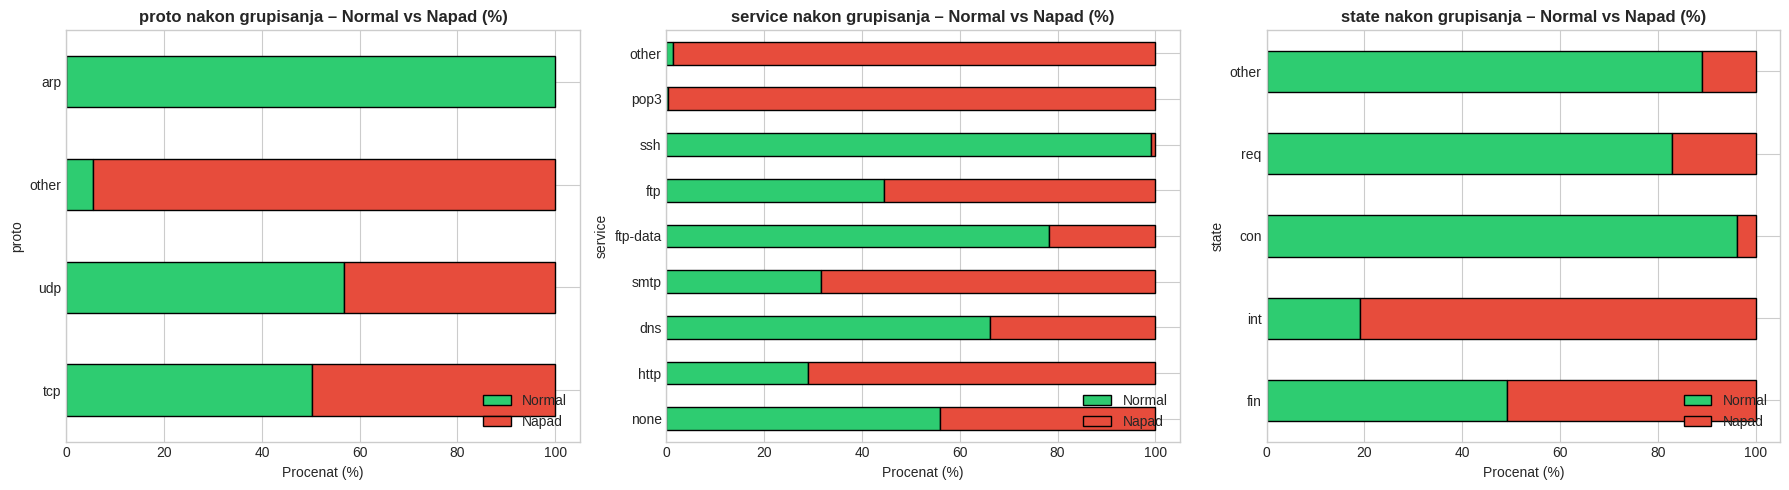

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, CAT_FEATURES):
    ct = pd.crosstab(df_tr[col], df_tr[TARGET], normalize='index') * 100
    ct = ct.loc[df_tr[col].value_counts().index]
    ct.plot(kind='barh', stacked=True, ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
    ax.set_title(f'{col} nakon grupisanja – Normal vs Napad (%)', fontweight='bold')
    ax.set_xlabel('Procenat (%)')
    ax.legend(['Normal', 'Napad'], loc='lower right')
plt.tight_layout()
plt.show()

In [37]:
OHE_COLUMNS = [f'{col}_{cat}' for col in CAT_FEATURES for cat in CATEGORY_KEEP[col] + ['other']]

def one_hot_encode(df):
    dummies = pd.get_dummies(df[CAT_FEATURES], prefix=CAT_FEATURES, prefix_sep='_', dtype=np.int8)
    dummies = dummies.reindex(columns=OHE_COLUMNS, fill_value=0)
    return pd.concat([df.drop(columns=CAT_FEATURES), dummies], axis=1)

df_tr  = one_hot_encode(df_tr)
df_val = one_hot_encode(df_val)
df_te  = one_hot_encode(df_te)

print(f'✅ One-Hot enkodiranje: {len(CAT_FEATURES)} kolone -> {len(OHE_COLUMNS)} binarnih kolona')
print(OHE_COLUMNS)
print(f'\nTrain: {df_tr.shape} | Val: {df_val.shape} | Test: {df_te.shape}')

✅ One-Hot enkodiranje: 3 kolone -> 18 binarnih kolona
['proto_arp', 'proto_tcp', 'proto_udp', 'proto_other', 'service_dns', 'service_ftp', 'service_ftp-data', 'service_http', 'service_none', 'service_pop3', 'service_smtp', 'service_ssh', 'service_other', 'state_con', 'state_fin', 'state_int', 'state_req', 'state_other']

Train: (85689, 60) | Val: (15122, 60) | Test: (82332, 60)


In [38]:
# attack_cat se enkodira samo za kasniju analizu grešaka po tipu napada (glavni target je label)
le_attack = LabelEncoder()
le_attack.fit(pd.concat([df_tr[TARGET_MULTI], df_val[TARGET_MULTI], df_te[TARGET_MULTI]]))
attack_mapping = {cat: int(code) for cat, code in zip(le_attack.classes_, le_attack.transform(le_attack.classes_))}

print('=== Attack Category Encoding (pomoćni) ===')
for cat, code in attack_mapping.items():
    print(f'  {code}: {cat}')

=== Attack Category Encoding (pomoćni) ===
  0: Analysis
  1: Backdoor
  2: DoS
  3: Exploits
  4: Fuzzers
  5: Generic
  6: Normal
  7: Reconnaissance
  8: Shellcode
  9: Worms


In [39]:
CORR_THRESHOLD = 0.95

numeric_features = [c for c in df_tr.columns
                    if c not in OHE_COLUMNS + [TARGET, TARGET_MULTI, 'source']]

corr_matrix = df_tr[numeric_features].corr().abs()
target_corr = df_tr[numeric_features].corrwith(df_tr[TARGET]).abs()

pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))
pairs = pairs[pairs > CORR_THRESHOLD]

CORR_DROPPED = []
corr_report = []
for (f1, f2), value in pairs.items():
    if f1 in CORR_DROPPED or f2 in CORR_DROPPED:
        continue
    drop, keep = (f1, f2) if target_corr[f1] < target_corr[f2] else (f2, f1)
    CORR_DROPPED.append(drop)
    corr_report.append({'Zadržan': keep, 'Uklonjen': drop, 'Korelacija': round(value, 4),
                        '|corr| zadržanog sa label': round(target_corr[keep], 4),
                        '|corr| uklonjenog sa label': round(target_corr[drop], 4)})

print(f'Uklonjeno {len(CORR_DROPPED)} redundantnih atributa (korelacija > {CORR_THRESHOLD}):')
display(pd.DataFrame(corr_report))

Uklonjeno 6 redundantnih atributa (korelacija > 0.95):


,Zadržan,Uklonjen,Korelacija,|corr| zadržanog sa label,|corr| uklonjenog sa label
0,sbytes,sloss,0.9972,0.0463,0.0371
1,dloss,dbytes,0.9965,0.0554,0.0459
2,ct_ftp_cmd,is_ftp_login,0.9851,0.0032,0.0016
3,dwin,swin,0.9841,0.0517,0.0388
4,dpkts,dloss,0.9766,0.0652,0.0554
5,sbytes,spkts,0.9681,0.0463,0.0046


In [40]:
df_tr  = df_tr.drop(columns=CORR_DROPPED)
df_val = df_val.drop(columns=CORR_DROPPED)
df_te  = df_te.drop(columns=CORR_DROPPED)

numeric_features = [c for c in numeric_features if c not in CORR_DROPPED]
print(f'✅ Preostalo numeričkih atributa: {len(numeric_features)}')

✅ Preostalo numeričkih atributa: 33


In [41]:
MI_SAMPLE_SIZE = 60_000
MI_THRESHOLD = 0.001

candidate_features = numeric_features + OHE_COLUMNS
mi_sample = df_tr.sample(n=min(MI_SAMPLE_SIZE, len(df_tr)), random_state=RANDOM_STATE)

discrete_mask = [c in OHE_COLUMNS or c in BINARY_FEATURES for c in candidate_features]
print('Računanje Mutual Information... (može potrajati)')
mi_scores = mutual_info_classif(mi_sample[candidate_features], mi_sample[TARGET],
                                discrete_features=discrete_mask, random_state=RANDOM_STATE)

mi_df = (pd.DataFrame({'Feature': candidate_features, 'MI Score': mi_scores})
         .sort_values('MI Score', ascending=False).reset_index(drop=True))

print('\n=== Top 20 feature-a po Mutual Information ===')
display(mi_df.head(20))

Računanje Mutual Information... (može potrajati)

=== Top 20 feature-a po Mutual Information ===


,Feature,MI Score
0,sbytes,0.450154
1,sttl,0.401652
2,ct_state_ttl,0.393396
3,dttl,0.389109
4,dmean,0.323122
5,tcprtt,0.302879
6,synack,0.300169
7,rate,0.298563
8,ackdat,0.297227
9,dinpkt,0.293506


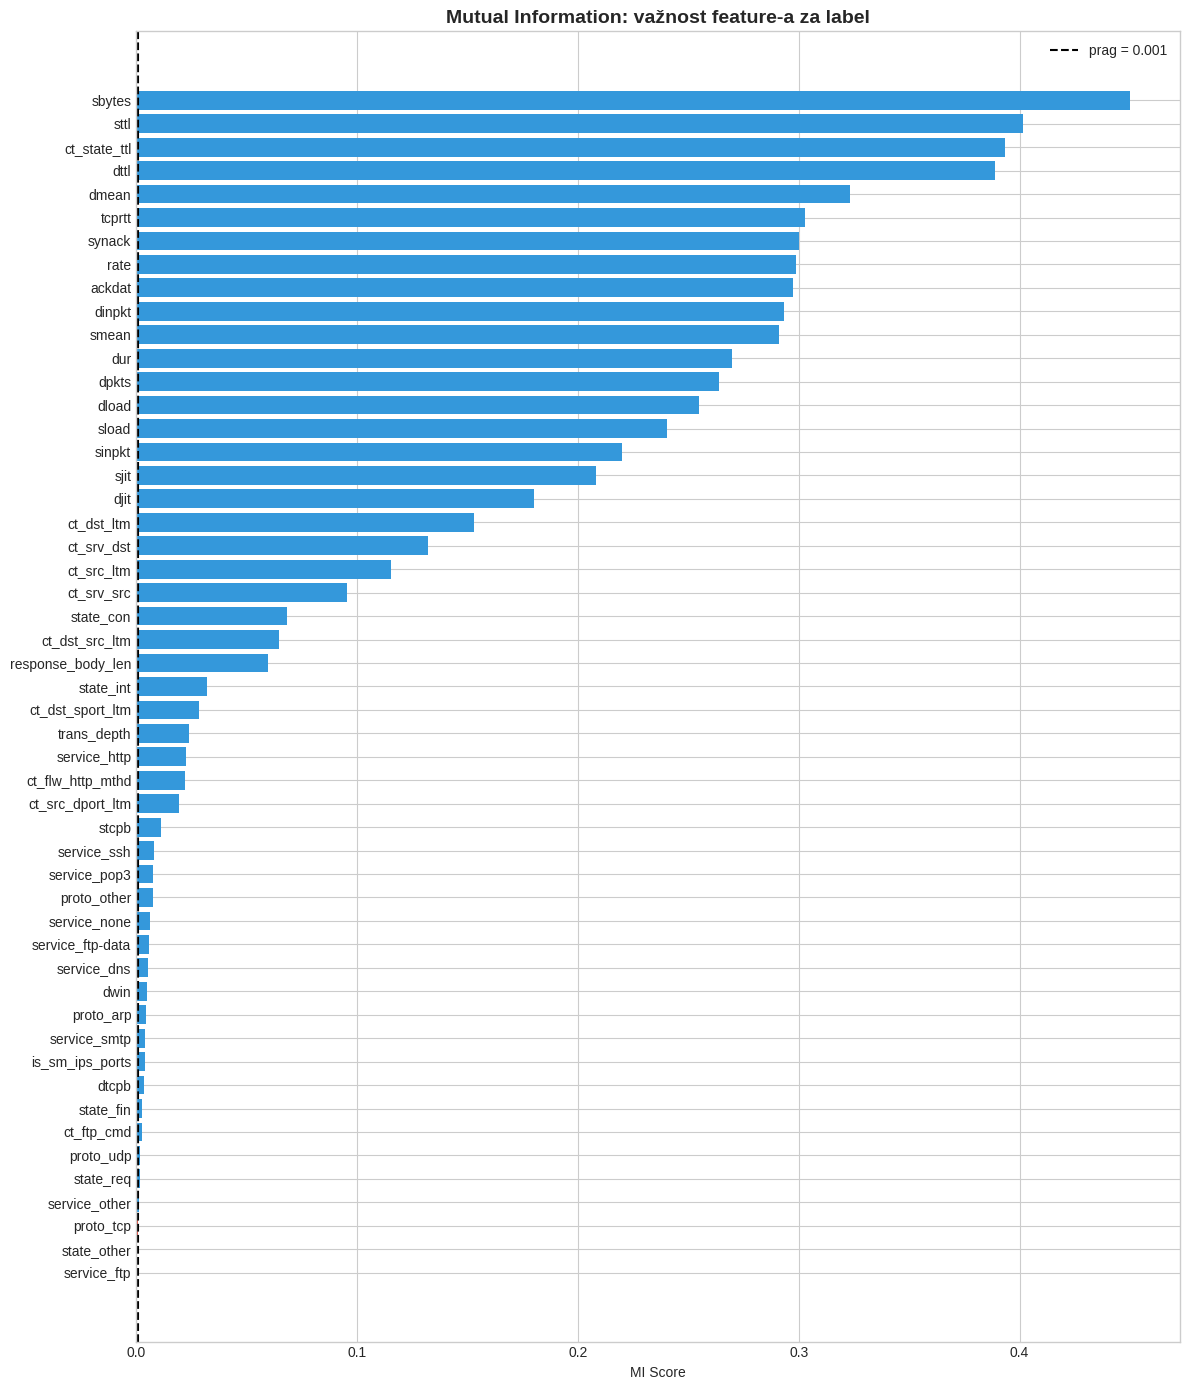

In [42]:
fig, ax = plt.subplots(figsize=(12, 14))
mi_sorted = mi_df.sort_values('MI Score', ascending=True)
colors = ['#e74c3c' if s < MI_THRESHOLD else '#3498db' for s in mi_sorted['MI Score']]
ax.barh(mi_sorted['Feature'], mi_sorted['MI Score'], color=colors)
ax.axvline(MI_THRESHOLD, color='black', linestyle='--', label=f'prag = {MI_THRESHOLD}')
ax.set_title('Mutual Information: važnost feature-a za label', fontsize=14, fontweight='bold')
ax.set_xlabel('MI Score')
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
# Uklanjaju se samo numerički atributi: pojedinačne one-hot kolone se ne izbacuju,
# jer bi to narušilo enkodiranje kategoričkog atributa kao cjeline
MI_DROPPED = mi_df.loc[(mi_df['MI Score'] < MI_THRESHOLD) & mi_df['Feature'].isin(numeric_features),
                       'Feature'].tolist()

df_tr  = df_tr.drop(columns=MI_DROPPED)
df_val = df_val.drop(columns=MI_DROPPED)
df_te  = df_te.drop(columns=MI_DROPPED)

numeric_features = [c for c in numeric_features if c not in MI_DROPPED]
ohe_features = [c for c in OHE_COLUMNS if c not in MI_DROPPED]

print(f'Uklonjeno {len(MI_DROPPED)} atributa sa MI < {MI_THRESHOLD}: {MI_DROPPED or "nijedan"}')
print(f'Preostalo: {len(numeric_features)} numeričkih + {len(ohe_features)} one-hot = {len(numeric_features) + len(ohe_features)} feature-a')

Uklonjeno 0 atributa sa MI < 0.001: nijedan
Preostalo: 33 numeričkih + 18 one-hot = 51 feature-a


In [44]:
SKEW_THRESHOLD = 1.0

continuous_features = [c for c in numeric_features if c not in BINARY_FEATURES]
skewness = df_tr[continuous_features].skew()
LOG_FEATURES = [c for c in continuous_features
                if skewness[c] > SKEW_THRESHOLD and df_tr[c].min() >= 0]

def apply_log(df):
    df = df.copy()
    df[LOG_FEATURES] = np.log1p(df[LOG_FEATURES].clip(lower=0))
    return df

df_tr_before_log = df_tr[continuous_features].copy()

df_tr  = apply_log(df_tr)
df_val = apply_log(df_val)
df_te  = apply_log(df_te)

skew_report = pd.DataFrame({
    'Skew prije': skewness[LOG_FEATURES],
    'Skew poslije': df_tr[LOG_FEATURES].skew()
}).round(2).sort_values('Skew prije', ascending=False)

print(f'✅ log1p primijenjen na {len(LOG_FEATURES)} od {len(continuous_features)} kontinualnih atributa')
display(skew_report)

✅ log1p primijenjen na 27 od 32 kontinualnih atributa


,Skew prije,Skew poslije
trans_depth,126.13,2.05
response_body_len,62.89,3.05
sbytes,33.71,0.89
dpkts,29.93,0.27
dinpkt,28.96,0.06
djit,26.54,0.07
sjit,18.75,-0.50
ct_flw_http_mthd,17.33,2.39
sinpkt,12.28,0.35
sload,9.73,0.61


In [45]:
SCALE_FEATURES = continuous_features

scaler = RobustScaler()
scaler.fit(df_tr[SCALE_FEATURES])

# Kod atributa gdje je IQR = 0 (npr. dwin: većina zapisa ima istu vrijednost) RobustScaler
# ne skalira ništa (dijeli sa 1), pa bi vrijednosti ostale u originalnom rasponu (0-255).
# Za takve atribute kao rezerva se koristi standardna devijacija sa train skupa.
iqr = df_tr[SCALE_FEATURES].quantile(0.75) - df_tr[SCALE_FEATURES].quantile(0.25)
ZERO_IQR_FEATURES = iqr[iqr == 0].index.tolist()
for col in ZERO_IQR_FEATURES:
    std = df_tr[col].std()
    scaler.scale_[SCALE_FEATURES.index(col)] = std if std > 0 else 1.0
print(f'Atributi sa IQR = 0 (skalirani standardnom devijacijom): {ZERO_IQR_FEATURES or "nema"}')

def apply_scaling(df):
    df = df.copy()
    df[SCALE_FEATURES] = scaler.transform(df[SCALE_FEATURES])
    return df

df_tr  = apply_scaling(df_tr)
df_val = apply_scaling(df_val)
df_te  = apply_scaling(df_te)

print(f'✅ RobustScaler primijenjen na {len(SCALE_FEATURES)} atributa (fit samo na train skupu)')
print('\nStatistika train skupa nakon transformacije:')
display(df_tr[SCALE_FEATURES].describe().T[['min', '25%', '50%', '75%', 'max']].round(3))

Atributi sa IQR = 0 (skalirani standardnom devijacijom): ['dwin', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd']
✅ RobustScaler primijenjen na 32 atributa (fit samo na train skupu)

Statistika train skupa nakon transformacije:


,min,25%,50%,75%,max
dur,-0.463,-0.455,0.0,0.545,5.494
dpkts,-1.531,-0.410,0.0,0.590,4.952
sbytes,-2.122,-0.370,0.0,0.630,5.686
rate,-0.922,-0.226,0.0,0.774,2.008
sttl,-0.278,-0.139,0.0,0.861,0.865
dttl,-0.130,0.000,0.0,1.000,1.009
sload,-2.453,-0.402,0.0,0.598,2.627
dload,-1.694,-0.230,0.0,0.770,1.432
sinpkt,-0.801,-0.715,0.0,0.285,2.024
dinpkt,-0.743,-0.690,0.0,0.310,1.834


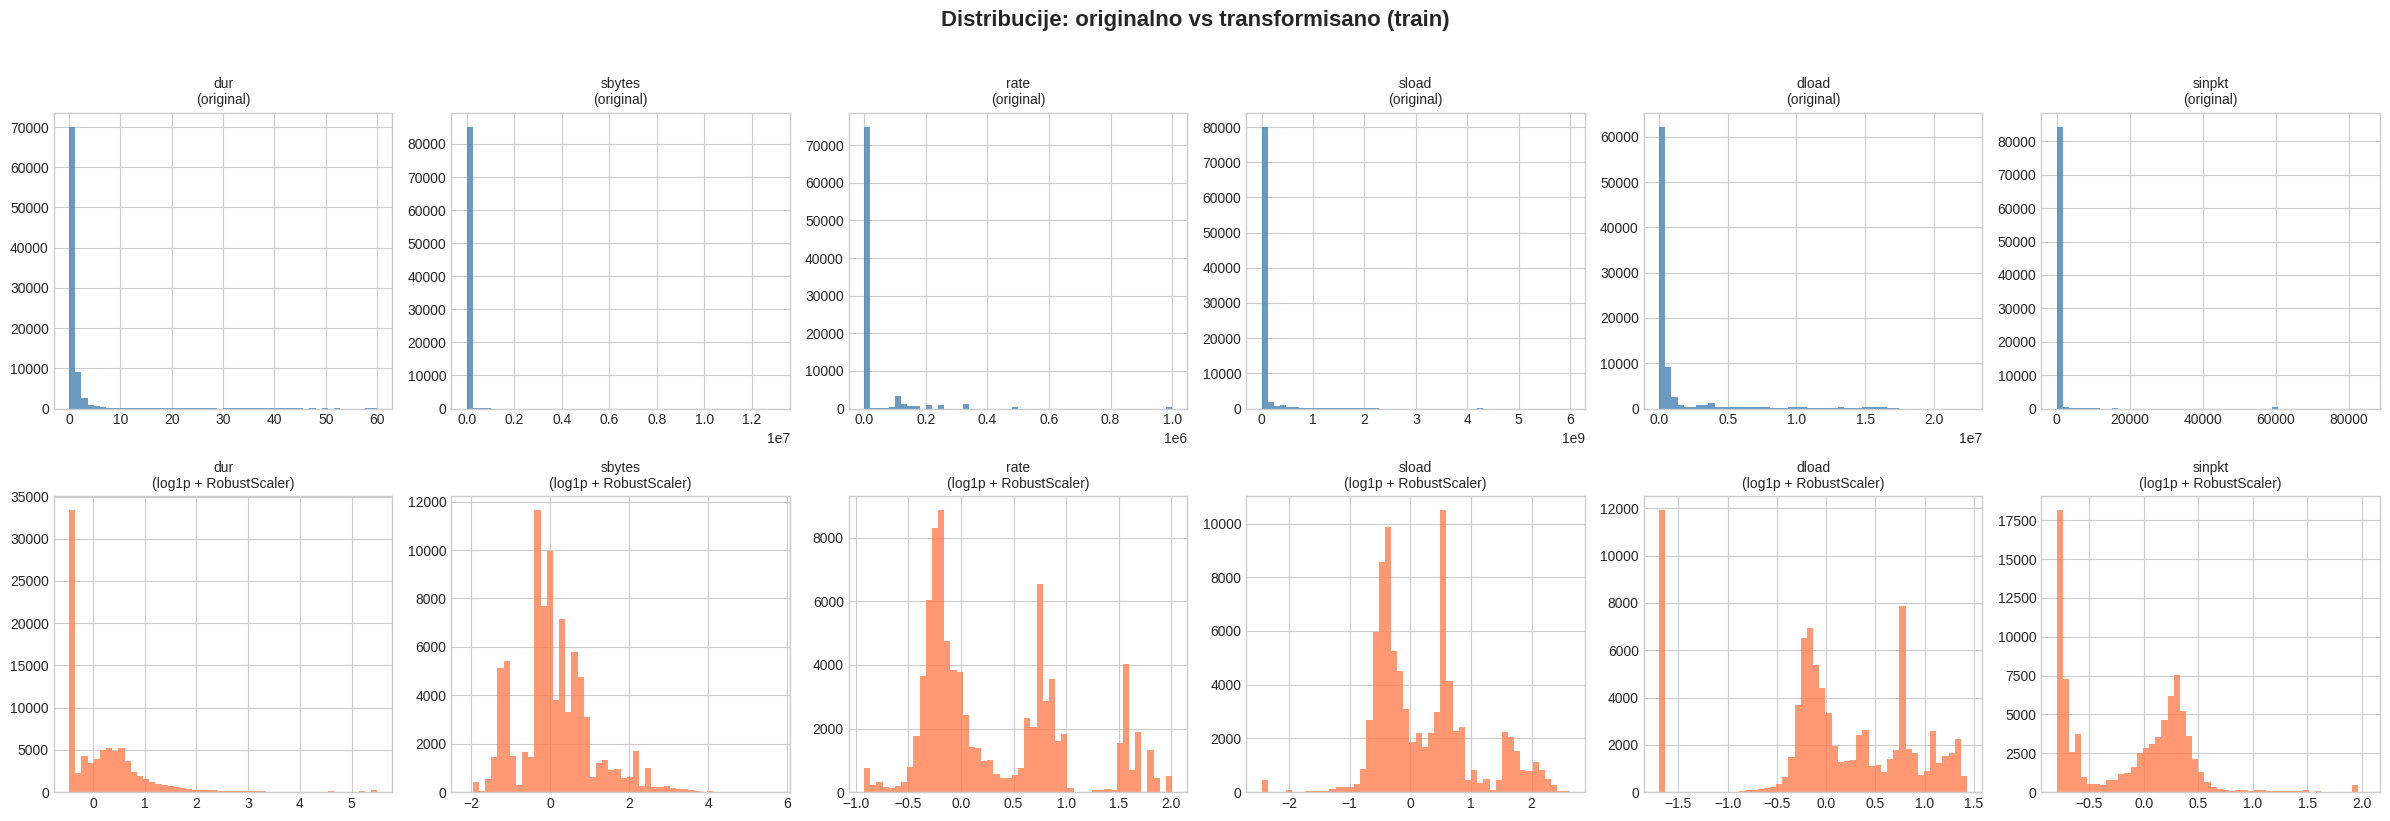

In [46]:
# Vizualizacija: original vs log1p + RobustScaler
sample_features = [f for f in ['dur', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sinpkt', 'smean']
                   if f in SCALE_FEATURES][:6]

fig, axes = plt.subplots(2, len(sample_features), figsize=(4 * len(sample_features), 8))
for idx, col in enumerate(sample_features):
    axes[0, idx].hist(df_tr_before_log[col], bins=50, color='steelblue', alpha=0.8)
    axes[0, idx].set_title(f'{col}\n(original)', fontsize=10)
    axes[1, idx].hist(df_tr[col], bins=50, color='coral', alpha=0.8)
    axes[1, idx].set_title(f'{col}\n(log1p + RobustScaler)', fontsize=10)

plt.suptitle('Distribucije: originalno vs transformisano (train)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [47]:
y_tr_counts = df_tr[TARGET].value_counts().sort_index()
print('=== Distribucija label u train skupu ===')
print(f'Normal (0): {y_tr_counts[0]:,} ({y_tr_counts[0]/len(df_tr)*100:.1f}%)')
print(f'Napad (1):  {y_tr_counts[1]:,} ({y_tr_counts[1]/len(df_tr)*100:.1f}%)')
print(f'Odnos: 1:{y_tr_counts.max()/y_tr_counts.min():.2f}')

class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=df_tr[TARGET])
class_weight_dict = {0: float(class_weights[0]), 1: float(class_weights[1])}

attack_classes = np.unique(le_attack.transform(df_tr[TARGET_MULTI]))
multi_weights = compute_class_weight('balanced', classes=attack_classes,
                                     y=le_attack.transform(df_tr[TARGET_MULTI]))
class_weight_multi_dict = {int(c): float(w) for c, w in zip(attack_classes, multi_weights)}

print('\n=== Class Weights – binarna klasifikacija (za model) ===')
print(f'  Normal (0): {class_weight_dict[0]:.4f}')
print(f'  Napad (1):  {class_weight_dict[1]:.4f}')

=== Distribucija label u train skupu ===
Normal (0): 43,911 (51.2%)
Napad (1):  41,778 (48.8%)
Odnos: 1:1.05

=== Class Weights – binarna klasifikacija (za model) ===
  Normal (0): 0.9757
  Napad (1):  1.0255


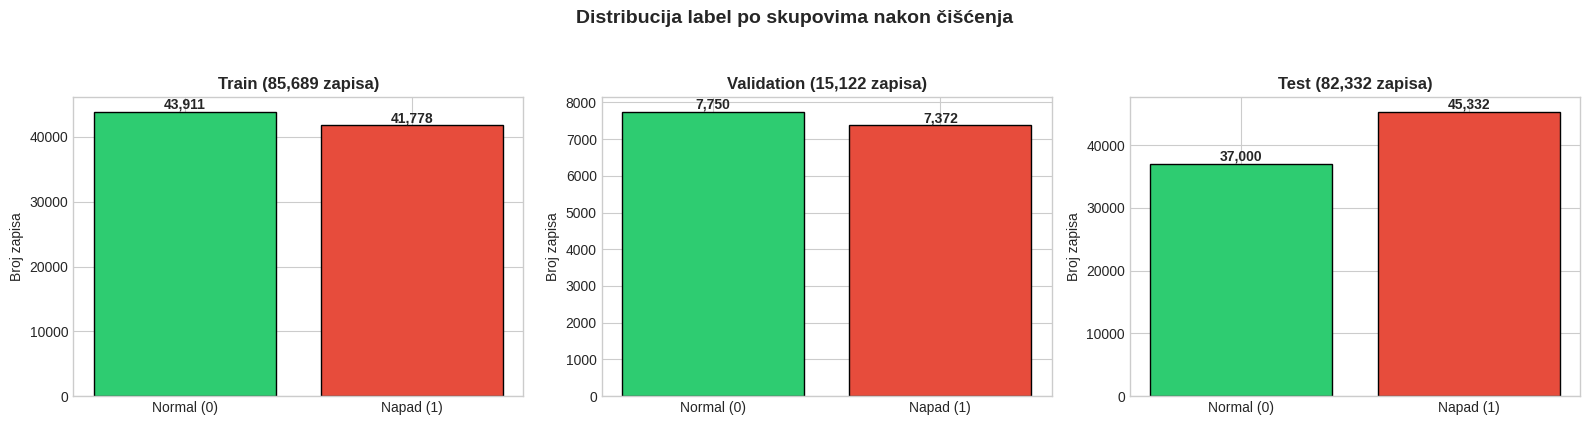

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, d) in zip(axes, (('Train', df_tr), ('Validation', df_val), ('Test', df_te))):
    counts = d[TARGET].value_counts().sort_index()
    bars = ax.bar(['Normal (0)', 'Napad (1)'], counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='black')
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')
    ax.set_title(f'{name} ({len(d):,} zapisa)', fontweight='bold')
    ax.set_ylabel('Broj zapisa')
plt.suptitle('Distribucija label po skupovima nakon čišćenja', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()